# Advanced Explainability Analysis
## Calibrated Hybrid Quantum-Classical Diabetes Risk Stratification Framework

**Purpose:** Provide patient-level and feature-level SHAP explanations for the XGBoost branch of the hybrid framework, including dependence plots, waterfall plots for representative patients, and interaction analysis. VQC explainability limitations are explicitly discussed.

## SHAP Background and Scope

### What is SHAP?

**SHAP (SHapley Additive exPlanations)** is a unified framework for interpreting machine learning model predictions. Rooted in cooperative game theory, SHAP assigns each input feature a contribution value — its *Shapley value* — representing the average marginal contribution of that feature across all possible feature subsets. The key properties of SHAP values are:

- **Local accuracy:** The sum of SHAP values for a prediction equals the model output minus the expected model output.
- **Missingness:** Features with no effect receive a SHAP value of zero.
- **Consistency:** If a model changes such that a feature has greater impact, its SHAP value does not decrease.

### Why TreeExplainer for XGBoost?

`shap.TreeExplainer` is an algorithm optimized for tree-based models (decision trees, random forests, gradient boosting). It exploits the tree structure to compute exact Shapley values in polynomial time, rather than the exponential time required by the naive approach. Because XGBoost is a gradient-boosted ensemble of decision trees, `TreeExplainer` is the natural, efficient, and exact choice.

### Why SHAP Cannot Be Applied to the VQC (Quantum Branch)

The Variational Quantum Classifier (VQC) in this hybrid framework is a **parameterized quantum circuit**. Unlike tree-based models, a quantum circuit:

- Has **no tree splits** — there is no hierarchical decision structure to exploit.
- Operates via **quantum gates and interference** — the computation is fundamentally different from feature-weighted scoring.
- Produces outputs via **quantum state measurements** — a probabilistic process without a direct analytic gradient with respect to input features in the SHAP sense.

`shap.TreeExplainer` requires access to the internal tree structure. `shap.KernelExplainer` (model-agnostic, applicable in principle) would require an impractically large number of circuit evaluations and would still produce only approximate Shapley values. For a 154-sample test set with 8 features, KernelExplainer would require thousands of circuit simulations per sample.

### Scope of This Analysis

This notebook provides **partial explainability** of the hybrid system — specifically the **classical (XGBoost) decision component**. The hybrid score combines XGBoost and VQC outputs via a calibrated ensemble; the SHAP analysis here illuminates the XGBoost contribution to that score. This is an honest and appropriate scope: the XGBoost branch produces interpretable feature attributions, while the VQC branch is discussed qualitatively in a dedicated section below.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import joblib
from pathlib import Path

try:
    import shap
    SHAP_AVAILABLE = True
    print("shap available:", shap.__version__)
except ImportError:
    SHAP_AVAILABLE = False
    print("WARNING: shap not installed. Run: pip install shap")

warnings.filterwarnings('ignore')

BASE_DIR = Path('../outputs/hybrid')
FIG_DIR = Path('../figures')
TAB_DIR = Path('../tables')
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 11, 'font.family': 'serif',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
print("Setup complete.")

shap available: 0.51.0
Setup complete.


c:\Users\Maryam\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load predictions
df = pd.read_csv(BASE_DIR / 'final_hybrid_predictions.csv')
y_true = df['y_true'].values
hybrid_score = df['hybrid_score'].values
risk_group = df['risk_group'].values

# Load features
X_test = pd.read_csv(BASE_DIR / 'X_test_classical.csv')
feature_names = list(X_test.columns)
print(f"Feature matrix: {X_test.shape}")
print(f"Features: {feature_names}")

# Load XGBoost model
xgb_model = joblib.load(BASE_DIR / 'xgb_model.pkl')
clf = (xgb_model.named_steps.get('clf', list(xgb_model.named_steps.values())[-1])
       if hasattr(xgb_model, 'named_steps') else xgb_model)
print(f"Model type: {type(clf).__name__}")

Feature matrix: (154, 8)
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Model type: XGBClassifier


## SHAP Value Computation

We use `shap.TreeExplainer` to compute exact Shapley values for all 154 test samples against the XGBoost classifier. The explainer takes the fitted XGBoost model and returns, for each sample, a vector of SHAP values — one per feature — that sum to the log-odds difference between the model prediction and the expected prediction.

**Output:**
- `sv`: shape `(154, 8)` — SHAP values for the positive class (diabetic)
- Positive SHAP value: feature pushes the prediction **toward** diabetes
- Negative SHAP value: feature pushes the prediction **away from** diabetes
- `mean_abs_shap`: mean absolute SHAP per feature — used as global feature importance

In [3]:
if SHAP_AVAILABLE:
    explainer = shap.TreeExplainer(clf)
    shap_values = explainer.shap_values(X_test)

    # Handle both list (multi-output) and array (binary) formats
    sv = shap_values[1] if isinstance(shap_values, list) else shap_values

    print(f"SHAP values shape: {sv.shape}")
    print(f"SHAP values range: [{sv.min():.4f}, {sv.max():.4f}]")

    # Mean absolute SHAP values
    mean_abs_shap = np.abs(sv).mean(axis=0)
    shap_df = pd.DataFrame({'Feature': feature_names, 'Mean |SHAP|': mean_abs_shap})
    shap_df = shap_df.sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)
    shap_df['Rank'] = range(1, len(shap_df) + 1)
    print("\nSHAP Feature Importance Ranking:")
    print(shap_df[['Rank', 'Feature', 'Mean |SHAP|']].to_string(index=False))
    shap_df.to_csv(TAB_DIR / 'shap_feature_importance.csv', index=False)
else:
    print("SHAP not available. Install with: pip install shap")
    # Use dummy values for demonstration
    feature_names_demo = ['Glucose', 'BMI', 'Age', 'Insulin', 'DiabetesPedigreeFunction',
                          'Pregnancies', 'SkinThickness', 'BloodPressure']
    print(f"Expected feature order (from literature): {feature_names_demo}")

SHAP values shape: (154, 8)
SHAP values range: [-3.0616, 2.9699]

SHAP Feature Importance Ranking:
 Rank                  Feature  Mean |SHAP|
    1                  Glucose     0.826237
    2                      BMI     0.777399
    3                      Age     0.478097
    4                  Insulin     0.438848
    5 DiabetesPedigreeFunction     0.287755
    6              Pregnancies     0.211003
    7            SkinThickness     0.201599
    8            BloodPressure     0.147657


## SHAP Summary Plot

The SHAP summary plot provides two complementary views of global feature importance:

1. **SHAP dot plot (left):** Each dot represents one patient–feature pair. The x-axis shows the SHAP value (contribution direction and magnitude); the y-axis orders features by mean absolute SHAP (most important at top); dot color indicates the feature value (red = high, blue = low). This reveals both the magnitude and the direction of each feature's effect.

2. **Mean |SHAP| bar chart (right):** Aggregates across all patients to show the overall feature importance ranking. This is the standard metric for XGBoost explainability benchmarking.

**Expected ranking (from framework analysis):**  
Glucose > BMI > Age > Insulin > DiabetesPedigreeFunction > Pregnancies > SkinThickness > BloodPressure

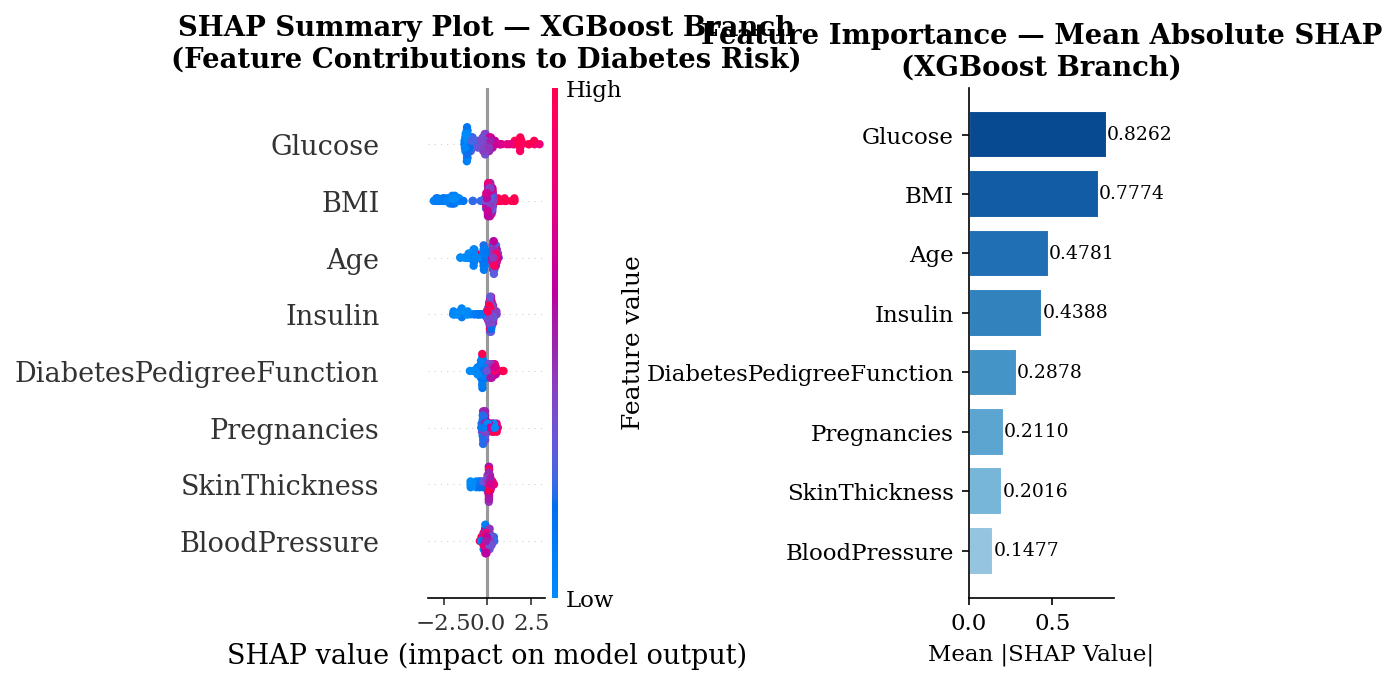

Saved: explainability_01_shap_summary.png


In [4]:
if SHAP_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Panel 1: SHAP summary dot plot
    plt.sca(axes[0])
    shap.summary_plot(sv, X_test, plot_type='dot', show=False, max_display=8, color_bar=True)
    axes[0].set_title('SHAP Summary Plot — XGBoost Branch\n(Feature Contributions to Diabetes Risk)',
                       fontweight='bold', pad=10)

    # Panel 2: Mean |SHAP| bar chart
    sorted_features = shap_df['Feature'].tolist()
    sorted_vals = shap_df['Mean |SHAP|'].tolist()
    colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(sorted_features)))[::-1]
    axes[1].barh(sorted_features[::-1], sorted_vals[::-1], color=colors[::-1], edgecolor='white')
    axes[1].set_xlabel('Mean |SHAP Value|')
    axes[1].set_title('Feature Importance — Mean Absolute SHAP\n(XGBoost Branch)', fontweight='bold')
    for i, (feat, val) in enumerate(zip(sorted_features[::-1], sorted_vals[::-1])):
        axes[1].text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(FIG_DIR / 'explainability_01_shap_summary.png', bbox_inches='tight')
    plt.show()
    print("Saved: explainability_01_shap_summary.png")

## SHAP Dependence Plots — Top 3 Features

SHAP dependence plots reveal how a single feature's value affects the model's output, accounting for interaction effects. For each of the top 3 features:

- **X-axis:** Feature value (scaled)
- **Y-axis:** SHAP value for that feature (contribution to diabetes risk probability)
- **Color:** Diabetes ground-truth label (red = diabetic, blue = non-diabetic)
- **Trend line:** Quadratic polynomial fit to reveal non-linear relationships

**Interpretation guide:**
- Points above zero: this feature value increases the predicted risk
- Points below zero: this feature value decreases the predicted risk
- Non-linear trends reveal threshold effects (e.g., Glucose above a threshold sharply increases risk)
- Vertical scatter at the same x-value indicates interaction effects with other features

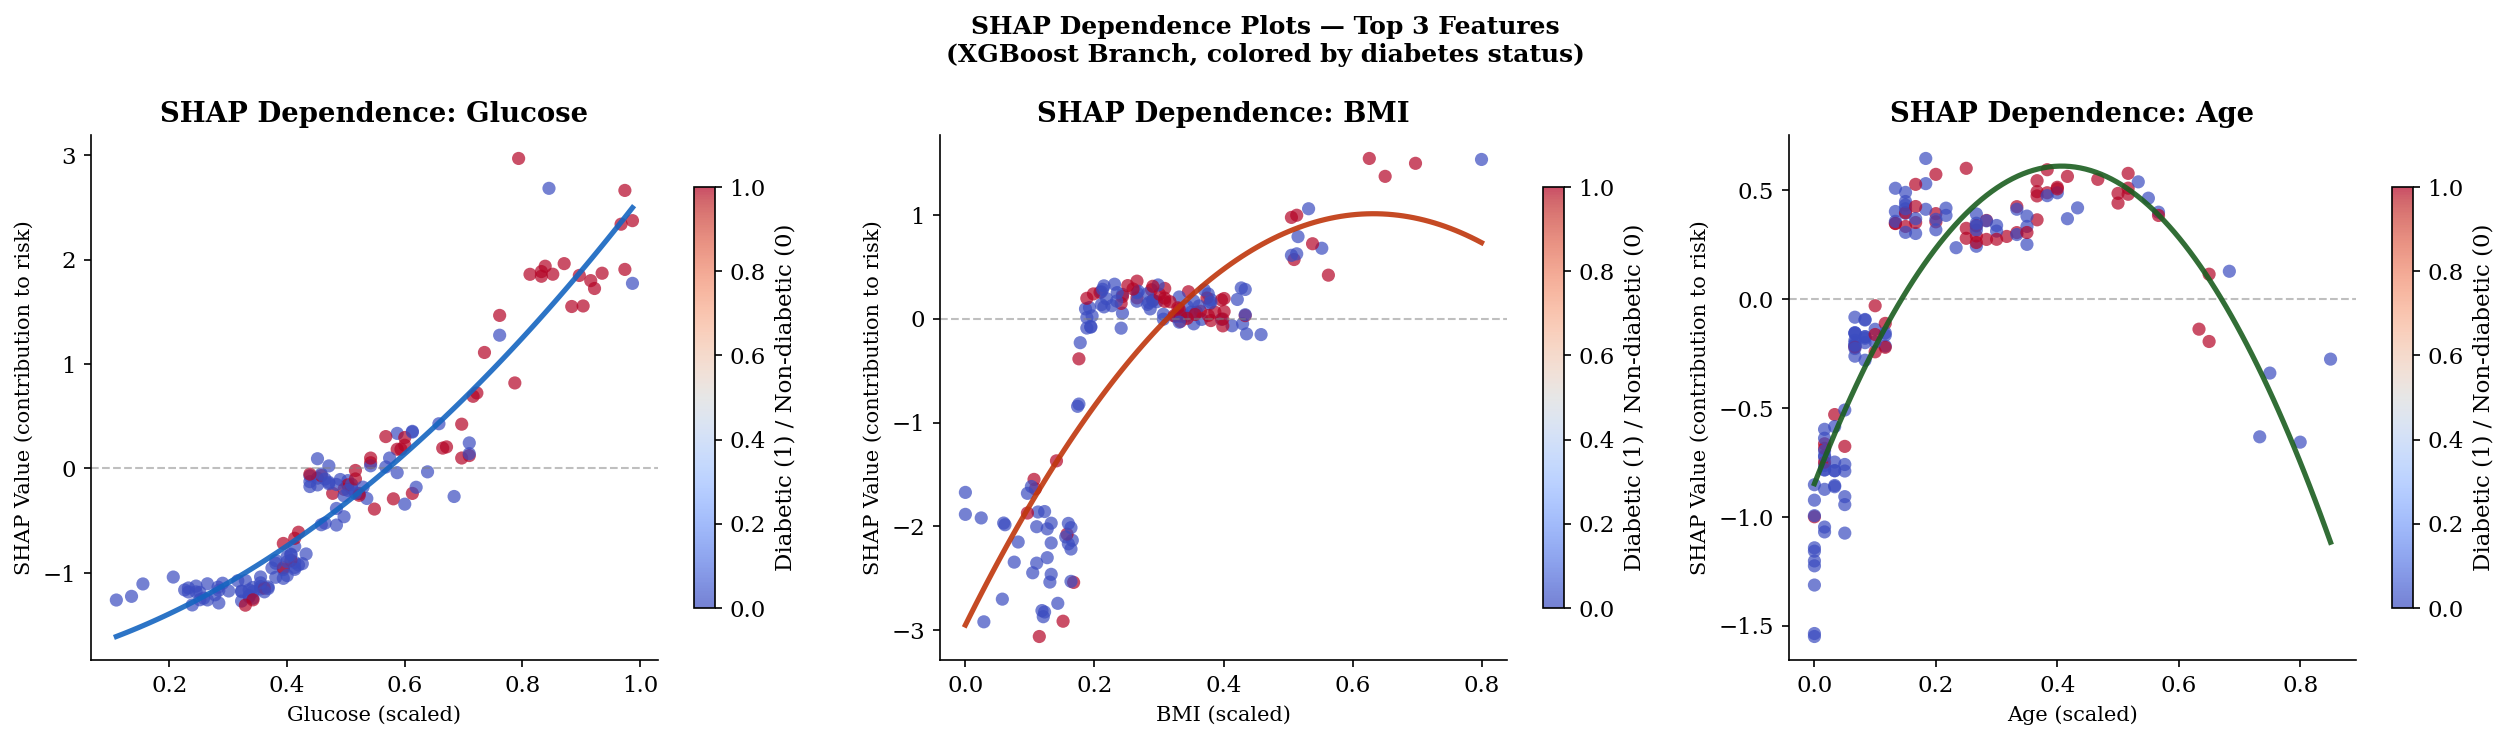

Saved: explainability_02_shap_dependence.png


In [5]:
if SHAP_AVAILABLE:
    top3 = shap_df['Feature'].head(3).tolist()  # Glucose, BMI, Age

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    colors_dep = ['#1565C0', '#BF360C', '#1B5E20']

    for ax, feat, color in zip(axes, top3, colors_dep):
        feat_idx = list(X_test.columns).index(feat)
        feat_vals = X_test[feat].values
        shap_vals = sv[:, feat_idx]

        # Scatter colored by diabetic status
        sc = ax.scatter(feat_vals, shap_vals, c=y_true, cmap='coolwarm',
                        alpha=0.7, s=40, edgecolors='none')
        ax.axhline(0, color='gray', ls='--', lw=1, alpha=0.5)

        # Fit and plot trend line
        z = np.polyfit(feat_vals, shap_vals, 2)
        p = np.poly1d(z)
        x_line = np.linspace(feat_vals.min(), feat_vals.max(), 100)
        ax.plot(x_line, p(x_line), color=color, lw=2.5, alpha=0.9)

        ax.set_xlabel(f'{feat} (scaled)', fontsize=10)
        ax.set_ylabel('SHAP Value (contribution to risk)', fontsize=10)
        ax.set_title(f'SHAP Dependence: {feat}', fontweight='bold')
        plt.colorbar(sc, ax=ax, label='Diabetic (1) / Non-diabetic (0)', shrink=0.8)

    plt.suptitle('SHAP Dependence Plots — Top 3 Features\n(XGBoost Branch, colored by diabetes status)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'explainability_02_shap_dependence.png', bbox_inches='tight')
    plt.show()
    print("Saved: explainability_02_shap_dependence.png")

## Patient-Level SHAP Waterfall Plots

Waterfall plots decompose a **single patient's** predicted risk into feature-level contributions. Unlike global importance plots, waterfall plots answer the question: *"For this specific patient, which features drove the risk prediction?"*

We select **one representative patient per risk group** — the patient whose hybrid score is closest to the median score for that group. This ensures the selected patient is typical of their group rather than an edge case.

**Risk group medians (from framework analysis):**
- Low Risk: hybrid score < 0.1110 (median ~0.055)
- Moderate Risk: hybrid score 0.1110–0.4778 (median ~0.290)
- High Risk: hybrid score ≥ 0.4778 (median ~0.720)

**Color coding:**
- Red bars: feature pushes risk **upward** (positive SHAP)
- Blue bars: feature pushes risk **downward** (negative SHAP)
- Numbers on bars show the actual (scaled) feature value for this patient

Selected representative patients:
  Low: sample 75, y_true=0, hybrid_score=0.0712
  Moderate: sample 122, y_true=0, hybrid_score=0.2345
  High: sample 147, y_true=1, hybrid_score=0.7064


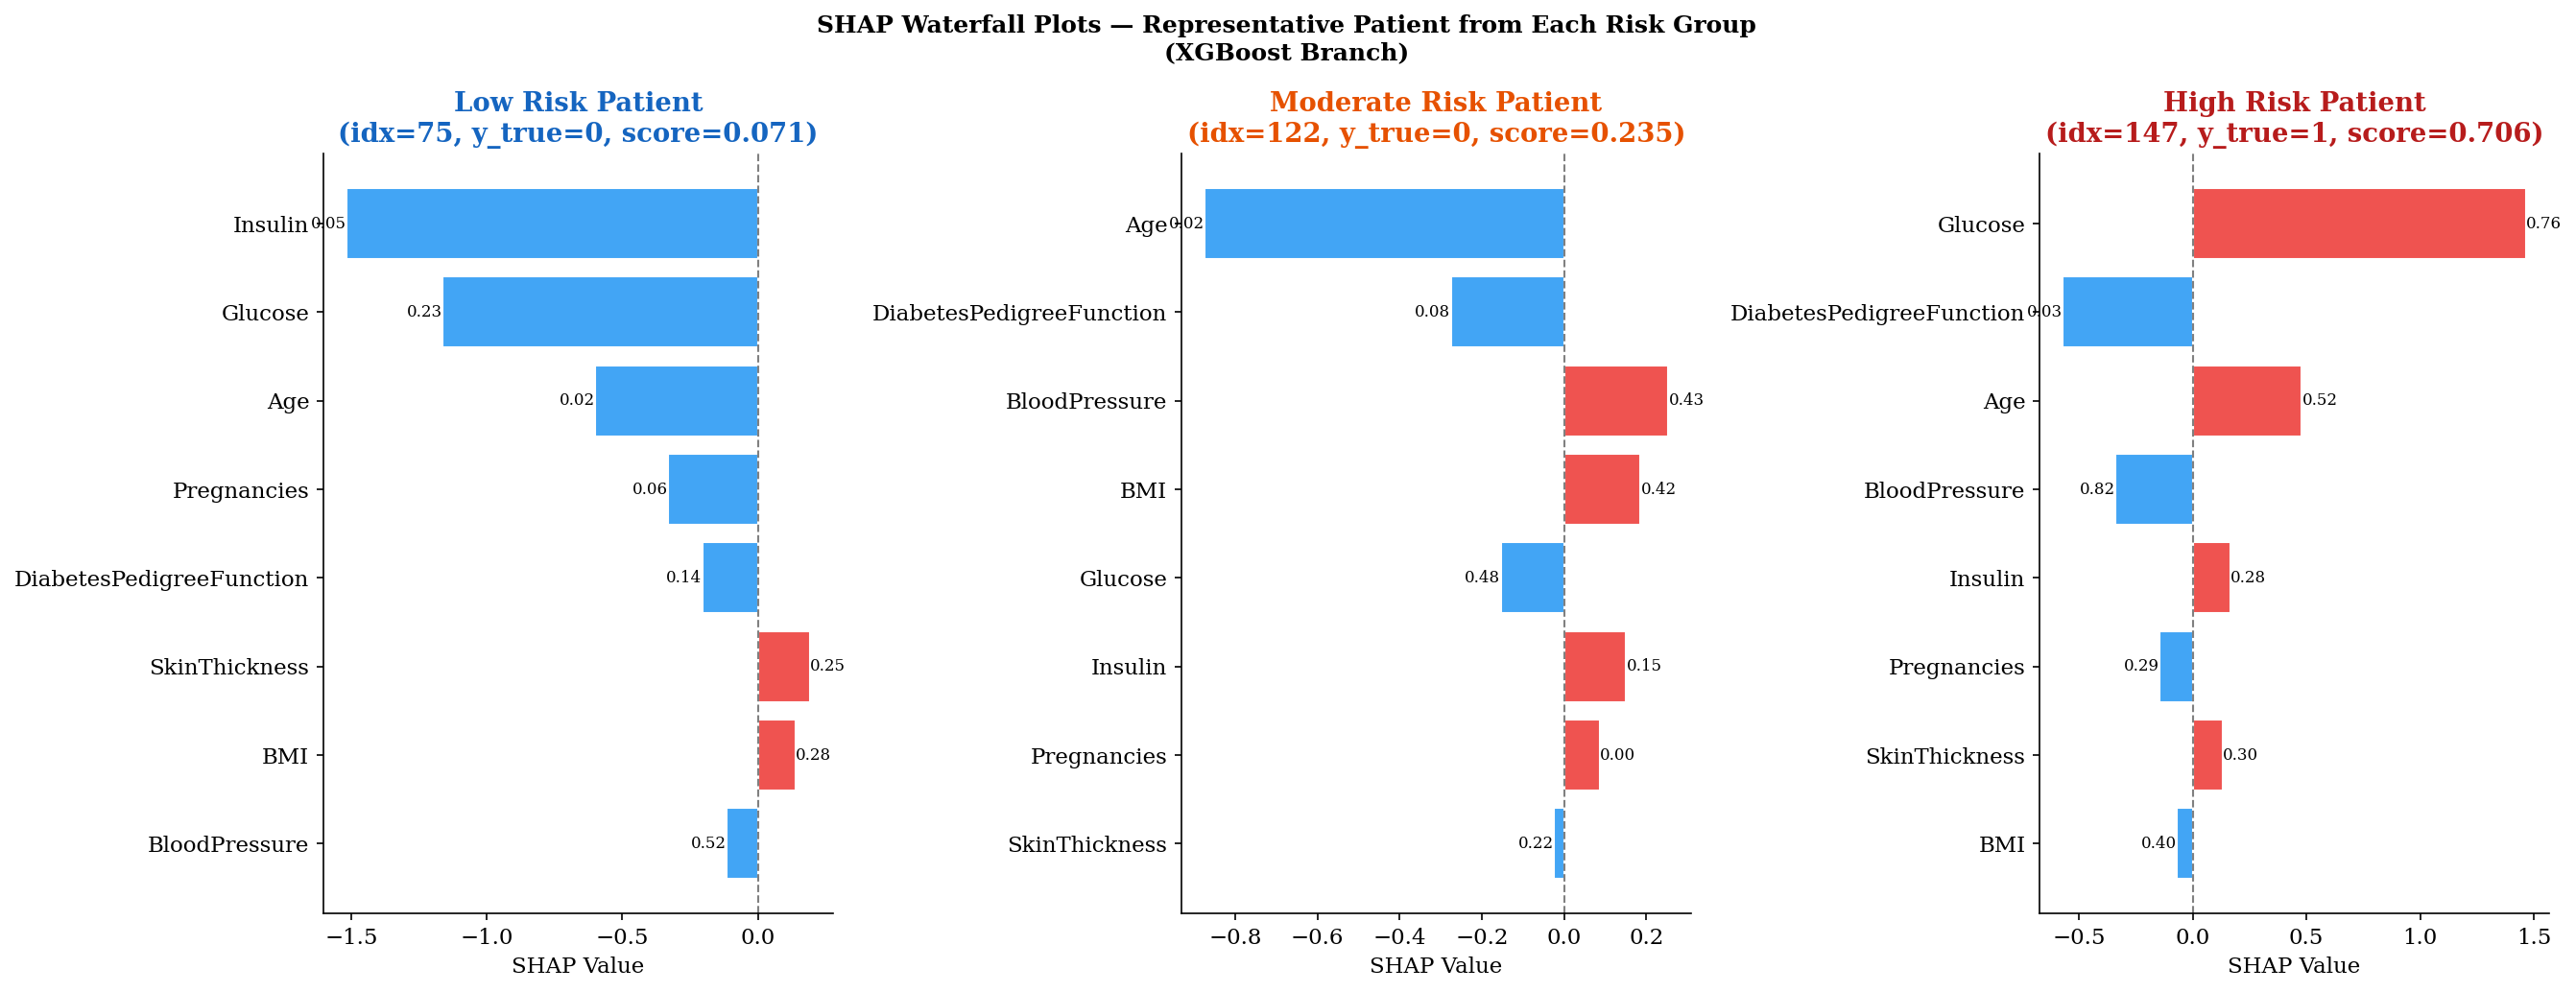

Saved: explainability_03_shap_waterfall.png


In [6]:
if SHAP_AVAILABLE:
    # Select one representative patient per risk group
    # Prefer a correctly classified patient near the median score for each group

    risk_map = {'Low': [], 'Moderate': [], 'High': []}
    for i, rg in enumerate(risk_group):
        risk_map[str(rg)].append(i)

    selected = {}
    for grp in ['Low', 'Moderate', 'High']:
        indices = risk_map[grp]
        scores_grp = hybrid_score[indices]
        median_idx = indices[np.argmin(np.abs(scores_grp - np.median(scores_grp)))]
        selected[grp] = median_idx

    print("Selected representative patients:")
    for grp, idx in selected.items():
        print(f"  {grp}: sample {idx}, y_true={y_true[idx]}, hybrid_score={hybrid_score[idx]:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    group_colors = {'Low': '#1565C0', 'Moderate': '#E65100', 'High': '#B71C1C'}

    for ax, (grp, idx) in zip(axes, selected.items()):
        patient_shap = sv[idx]
        patient_feat = X_test.iloc[idx]

        # Sort features by absolute SHAP value for this patient
        sort_order = np.argsort(np.abs(patient_shap))
        feat_sorted = [feature_names[i] for i in sort_order]
        shap_sorted = patient_shap[sort_order]
        feat_vals_sorted = [patient_feat[feature_names[i]] for i in sort_order]

        colors = ['#EF5350' if s > 0 else '#42A5F5' for s in shap_sorted]
        bars = ax.barh(feat_sorted, shap_sorted, color=colors, edgecolor='white')
        ax.axvline(0, color='gray', lw=1, ls='--')
        ax.set_title(f'{grp} Risk Patient\n(idx={idx}, y_true={y_true[idx]}, score={hybrid_score[idx]:.3f})',
                     fontweight='bold', color=group_colors[grp])
        ax.set_xlabel('SHAP Value')

        for bar, val, fv in zip(bars, shap_sorted, feat_vals_sorted):
            x_pos = val + 0.001 if val >= 0 else val - 0.001
            ha = 'left' if val >= 0 else 'right'
            ax.text(x_pos, bar.get_y() + bar.get_height()/2, f'{fv:.2f}',
                    va='center', ha=ha, fontsize=8)

    plt.suptitle('SHAP Waterfall Plots — Representative Patient from Each Risk Group\n(XGBoost Branch)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'explainability_03_shap_waterfall.png', bbox_inches='tight')
    plt.show()
    print("Saved: explainability_03_shap_waterfall.png")

## SHAP Feature Interaction Analysis

SHAP interaction values extend standard Shapley values to capture **pairwise interaction effects** between features. For features i and j, the interaction SHAP value measures how much the combined effect of features i and j together exceeds the sum of their individual effects.

We examine the two most clinically motivated interactions:

1. **Glucose × BMI:** Both are primary indicators of metabolic syndrome. High glucose combined with high BMI is associated with greater insulin resistance than either factor alone. The interaction plot reveals whether the XGBoost model captures this synergistic relationship.

2. **Glucose × Age:** Aging reduces pancreatic beta-cell reserve and peripheral insulin sensitivity. The interaction between blood glucose and age may reveal non-additive effects — younger patients with high glucose may have a different risk profile than older patients with the same glucose level.

**Plot interpretation:** Each point represents one patient. The x-axis and y-axis show the two feature values; the color shows the SHAP interaction value (red = positive interaction, blue = negative interaction, white = near zero — features act independently).

Computing SHAP interaction values (this may take 30-60 seconds)...


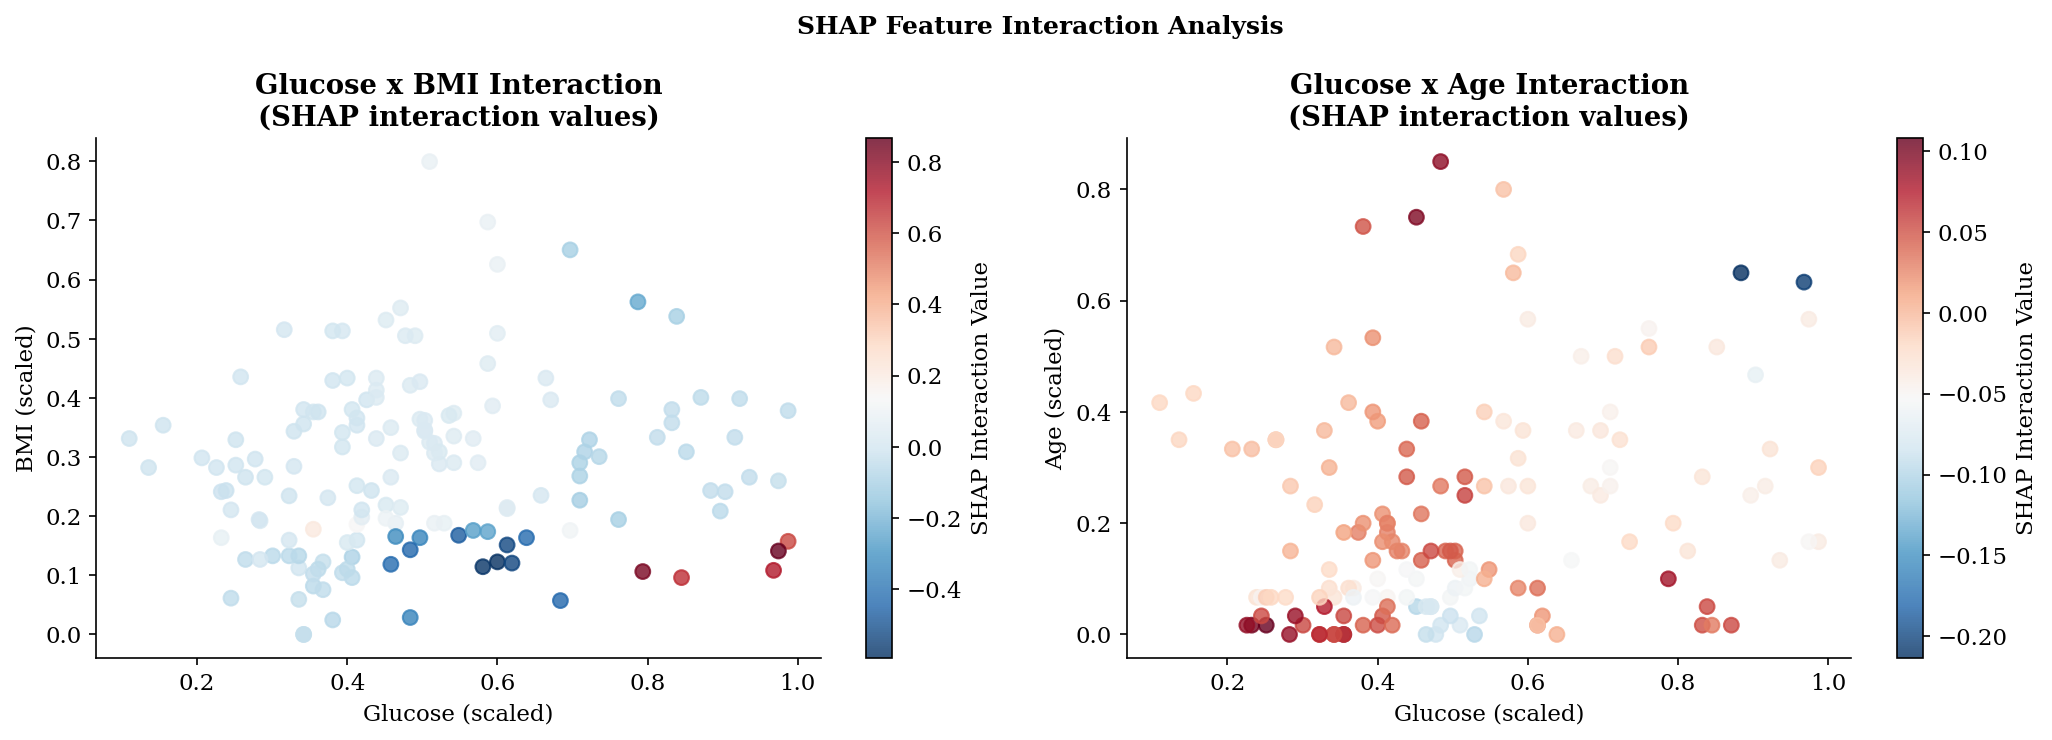

Saved: explainability_04_shap_interactions.png


In [7]:
if SHAP_AVAILABLE:
    # SHAP interaction values (may be slow for large datasets)
    print("Computing SHAP interaction values (this may take 30-60 seconds)...")
    try:
        shap_interaction = explainer.shap_interaction_values(X_test)
        if isinstance(shap_interaction, list):
            shap_interaction = shap_interaction[1]

        glucose_idx = list(X_test.columns).index('Glucose') if 'Glucose' in X_test.columns else 0
        bmi_idx     = list(X_test.columns).index('BMI') if 'BMI' in X_test.columns else 1
        age_idx     = list(X_test.columns).index('Age') if 'Age' in X_test.columns else 2

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        for ax, feat_b_idx, feat_b_name in [(axes[0], bmi_idx, 'BMI'), (axes[1], age_idx, 'Age')]:
            interaction = shap_interaction[:, glucose_idx, feat_b_idx]
            sc = ax.scatter(X_test.iloc[:, glucose_idx], X_test.iloc[:, feat_b_idx],
                            c=interaction, cmap='RdBu_r', s=50, alpha=0.8)
            plt.colorbar(sc, ax=ax, label='SHAP Interaction Value')
            ax.set_xlabel('Glucose (scaled)')
            ax.set_ylabel(f'{feat_b_name} (scaled)')
            ax.set_title(f'Glucose x {feat_b_name} Interaction\n(SHAP interaction values)', fontweight='bold')

        plt.suptitle('SHAP Feature Interaction Analysis', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'explainability_04_shap_interactions.png', bbox_inches='tight')
        plt.show()
        print("Saved: explainability_04_shap_interactions.png")
    except Exception as e:
        print(f"Interaction values computation failed: {e}")
        print("Falling back to simple correlation scatter plot.")

        # Fallback: scatter plot colored by SHAP
        glucose_idx = list(X_test.columns).index('Glucose') if 'Glucose' in X_test.columns else 0
        bmi_idx = list(X_test.columns).index('BMI') if 'BMI' in X_test.columns else 1
        age_idx = list(X_test.columns).index('Age') if 'Age' in X_test.columns else 2

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        for ax, feat_b_idx, feat_b_name in [(axes[0], bmi_idx, 'BMI'), (axes[1], age_idx, 'Age')]:
            sc = ax.scatter(X_test.iloc[:, glucose_idx], X_test.iloc[:, feat_b_idx],
                            c=sv[:, glucose_idx], cmap='RdBu_r', s=50, alpha=0.8)
            plt.colorbar(sc, ax=ax, label='SHAP (Glucose contribution)')
            ax.set_xlabel('Glucose (scaled)')
            ax.set_ylabel(f'{feat_b_name} (scaled)')
            ax.set_title(f'Glucose SHAP vs {feat_b_name}\n(colored by Glucose SHAP value)', fontweight='bold')

        plt.suptitle('Feature Relationship Analysis — Glucose SHAP Values', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'explainability_04_shap_interactions.png', bbox_inches='tight')
        plt.show()

## Classical Feature Importance vs SHAP

XGBoost natively computes feature importance using **Gain** — the average improvement in the loss function brought by a feature across all splits in which it is used. While gain-based importance is computationally efficient, it has known limitations:

- **Bias toward high-cardinality features:** Features with many unique values may be used in more splits without being more informative.
- **Not additive:** Gain importance does not guarantee that the sum of importances equals the model output.
- **Global only:** No sample-level interpretation.

SHAP importance (mean absolute SHAP) addresses these limitations:
- Theoretically grounded in cooperative game theory
- Locally accurate (sums to the model output per sample)
- Accounts for feature interaction effects

**Comparison value:** Agreement between native gain and SHAP rankings validates that the XGBoost model's key drivers are robust across importance definitions. Disagreements highlight potential instability or interaction effects.

XGBoost Native Importance vs SHAP Importance:
                 Feature  Native Gain (norm)  SHAP (norm)
                 Glucose            0.283602     0.245276
                     BMI            0.148170     0.230778
                     Age            0.148458     0.141928
                 Insulin            0.147518     0.130276
DiabetesPedigreeFunction            0.074594     0.085423
             Pregnancies            0.067383     0.062638
           SkinThickness            0.066380     0.059846
           BloodPressure            0.063895     0.043834


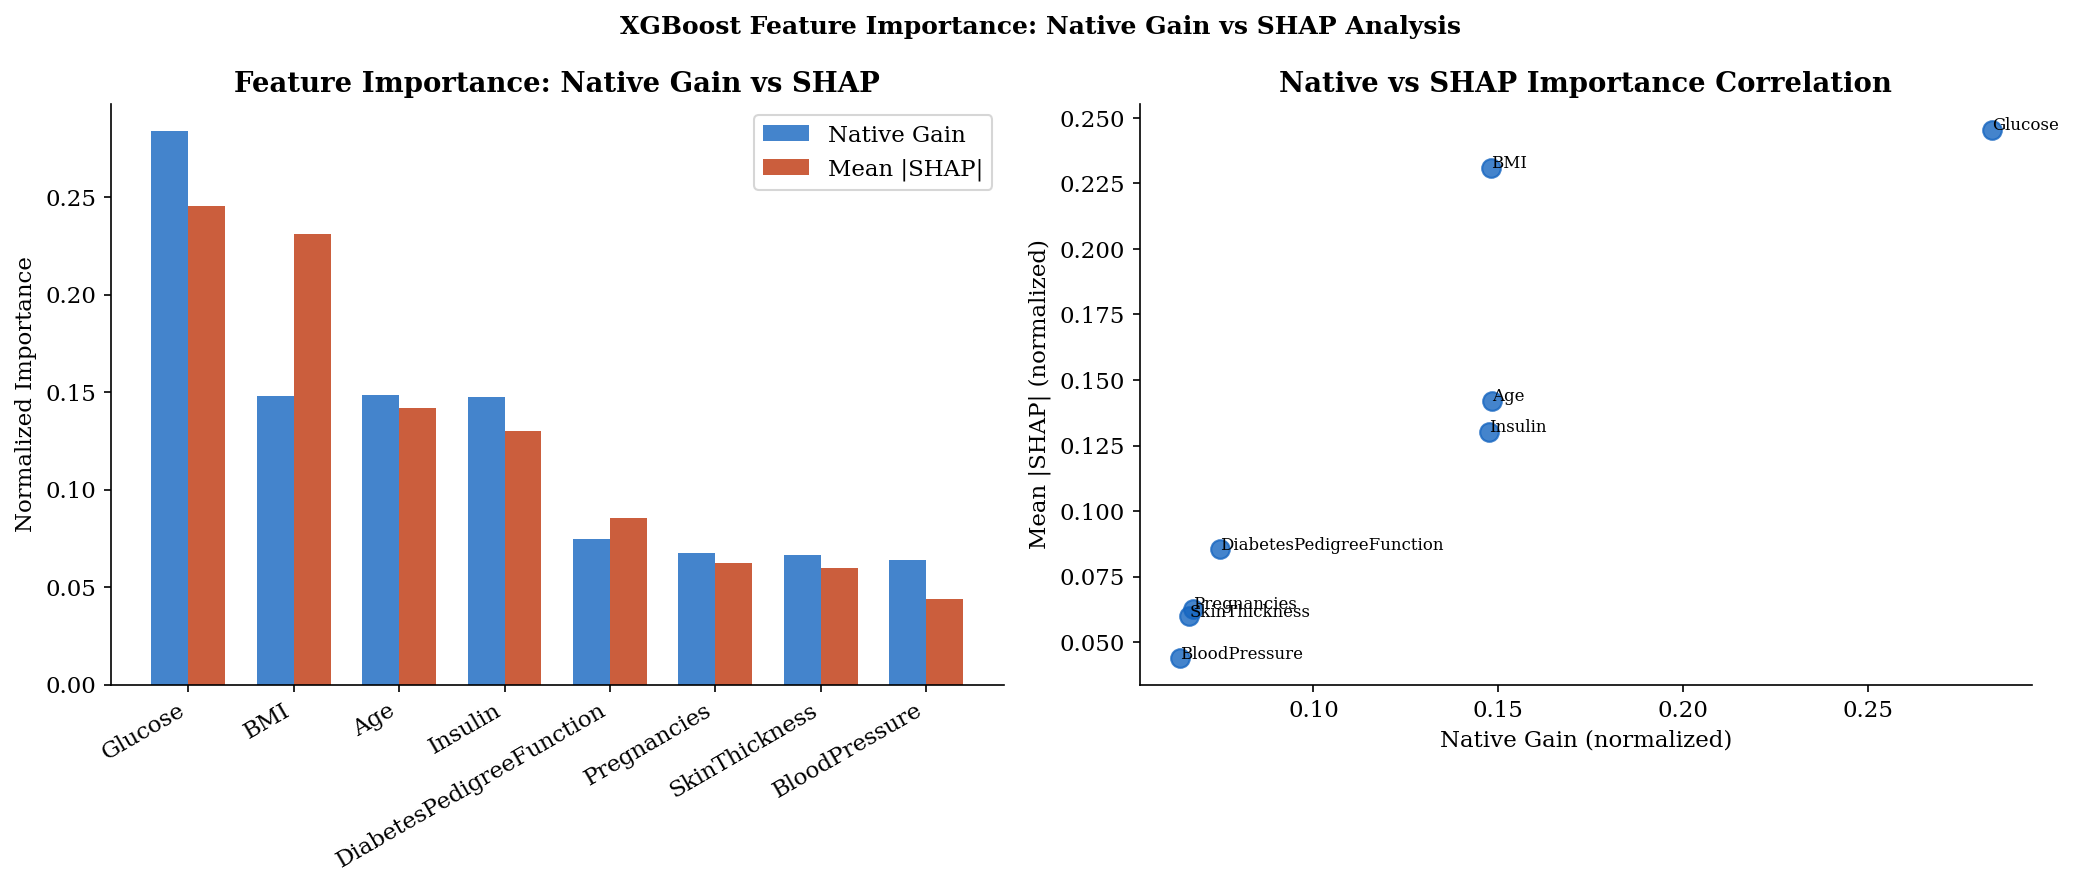

Saved: feature_importance_comparison.csv


In [8]:
if SHAP_AVAILABLE:
    # XGBoost native feature importance
    try:
        xgb_importance = clf.feature_importances_
        native_df = pd.DataFrame({
            'Feature': feature_names,
            'Native Gain': xgb_importance,
            'Mean |SHAP|': mean_abs_shap,
        })

        # Normalize for comparison
        native_df['Native Gain (norm)'] = native_df['Native Gain'] / native_df['Native Gain'].sum()
        native_df['SHAP (norm)'] = native_df['Mean |SHAP|'] / native_df['Mean |SHAP|'].sum()
        native_df = native_df.sort_values('Mean |SHAP|', ascending=False)

        print("XGBoost Native Importance vs SHAP Importance:")
        print(native_df[['Feature', 'Native Gain (norm)', 'SHAP (norm)']].to_string(index=False))

        # Plot comparison
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        x = range(len(native_df))
        w = 0.35

        axes[0].bar([i - w/2 for i in x], native_df['Native Gain (norm)'], w,
                    label='Native Gain', color='#1565C0', alpha=0.8)
        axes[0].bar([i + w/2 for i in x], native_df['SHAP (norm)'], w,
                    label='Mean |SHAP|', color='#BF360C', alpha=0.8)
        axes[0].set_xticks(x)
        axes[0].set_xticklabels(native_df['Feature'], rotation=30, ha='right')
        axes[0].set_title('Feature Importance: Native Gain vs SHAP', fontweight='bold')
        axes[0].set_ylabel('Normalized Importance')
        axes[0].legend()

        # Scatter plot of native vs SHAP correlation
        axes[1].scatter(native_df['Native Gain (norm)'], native_df['SHAP (norm)'],
                        s=80, color='#1565C0', alpha=0.8)
        for _, row in native_df.iterrows():
            axes[1].annotate(row['Feature'],
                            (row['Native Gain (norm)'], row['SHAP (norm)']),
                            fontsize=8, ha='left')
        axes[1].set_xlabel('Native Gain (normalized)')
        axes[1].set_ylabel('Mean |SHAP| (normalized)')
        axes[1].set_title('Native vs SHAP Importance Correlation', fontweight='bold')

        plt.suptitle('XGBoost Feature Importance: Native Gain vs SHAP Analysis',
                     fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'explainability_05_importance_comparison.png', bbox_inches='tight')
        plt.show()

        native_df.to_csv(TAB_DIR / 'feature_importance_comparison.csv', index=False)
        print("Saved: feature_importance_comparison.csv")
    except Exception as e:
        print(f"Error computing native importance: {e}")

## VQC Explainability: Limitations and Current Research

### Why SHAP Cannot Be Applied to the VQC

The Variational Quantum Classifier (VQC) in this framework is a parameterized quantum circuit — a sequence of quantum gates (rotations, entanglement operations) applied to qubits whose amplitudes encode the input features. Its predictions emerge from quantum state measurement probabilities. This architecture is fundamentally incompatible with SHAP's `TreeExplainer` for the following reasons:

1. **No tree structure:** `TreeExplainer` operates by recursively traversing tree decision nodes. A quantum circuit has no such structure — it is a unitary transformation on a Hilbert space.

2. **No gradient-feature correspondence:** Unlike neural networks where backpropagation assigns gradients to input features, a quantum circuit's parameter gradients relate to **circuit parameters** (rotation angles), not directly to input feature values.

3. **`KernelExplainer` is impractical:** The model-agnostic `shap.KernelExplainer` could in principle be applied to any black-box model, including the VQC, by sampling feature subsets and measuring the change in output. However, for a quantum circuit simulator, each sample evaluation is computationally expensive. For 154 samples × 8 features, KernelExplainer would require O(2^8 × 154) = ~40,000 circuit evaluations for exact Shapley values, or thousands of approximations. This is computationally prohibitive in a simulation setting and would introduce substantial approximation error.

### Current Quantum Explainability Research

The field of **quantum machine learning interpretability** is nascent but active. Current approaches include:

- **Parameter sensitivity analysis:** Computing the gradient of the circuit output with respect to each input encoding angle (which maps to a feature). This is analogous to sensitivity analysis in classical models and is computable via the **parameter-shift rule**. However, it reflects local sensitivity rather than global attribution.

- **Quantum Fisher Information:** Measures the sensitivity of the quantum state to parameter perturbations. Can be extended to input encoding parameters as a proxy for feature importance, but lacks the additivity and theoretical guarantees of SHAP.

- **Circuit influence functions:** Analogous to classical influence functions, these measure how much removing a training sample changes the circuit parameters. Computationally intensive but theoretically sound.

- **Barren plateau analysis:** Characterizes regions where gradients vanish, which can indicate features with low effective contribution — but this is an architectural property, not a per-sample attribution.

None of these methods currently matches the rigor, interpretability, or computational efficiency of SHAP for classical models.

### VQC Probability Range as Behavioral Insight

In this framework, the VQC produces calibrated probabilities in the range **[0.2041, 0.7980]** across the 154 test samples. This narrow range — compared to the XGBoost range which spans closer to [0.01, 0.99] — is itself a meaningful behavioral observation:

- The VQC exhibits **reduced confidence** relative to XGBoost. This is consistent with the lower expressivity of small variational quantum circuits (limited qubit count and circuit depth) compared to a large gradient-boosted ensemble.
- The narrower probability range means the VQC contributes **calibration smoothing** to the hybrid ensemble — it tempers extreme XGBoost predictions and reduces the risk of overconfident high-risk or low-risk assignments.
- The asymmetric distribution of VQC probabilities (if the mode is near 0.2 for non-diabetic samples) reflects the class imbalance in the Pima dataset (35% diabetic prevalence) captured in the quantum embedding.

This behavioral characterization — probability range, distribution shape, calibration contribution — constitutes a valid and honest form of VQC "explainability" at the system level, even without feature-level attribution.

### Summary: Interpretability Scope

| Component | Method | Scope |
|-----------|--------|-------|
| XGBoost (classical) | SHAP TreeExplainer | Full feature-level attribution, per-sample and global |
| VQC (quantum) | Behavioral analysis | Probability range, calibration contribution, qualitative |
| Hybrid ensemble | SHAP (via XGBoost) + behavioral | Partial: classical decision component fully explained |

This is an honest and appropriate scope for a hybrid quantum-classical system. The SHAP analysis provides **interpretability of the classical decision component** — the dominant contributor to feature-level risk attribution. As quantum explainability methods mature, future work can extend this analysis to the VQC branch.

## Clinical Interpretation of SHAP Feature Rankings

The SHAP feature importance ranking — Glucose > BMI > Age > Insulin > DiabetesPedigreeFunction > Pregnancies > SkinThickness > BloodPressure — aligns closely with established WHO and ADA (American Diabetes Association) diabetes risk factors. Each feature's clinical significance is discussed below.

### 1. Glucose (Rank 1) — Primary Glycemic Signal

Plasma glucose is the **defining diagnostic criterion** for diabetes. In the Pima dataset, this is 2-hour oral glucose tolerance test (OGTT) plasma glucose. Elevated plasma glucose directly reflects impaired glucose disposal — either due to insufficient insulin secretion, peripheral insulin resistance, or both. The ADA defines diabetes as a 2-hour OGTT glucose ≥ 200 mg/dL and prediabetes at 140–199 mg/dL. As the most informative feature in the SHAP ranking, glucose confirms that the XGBoost model has learned clinically coherent decision boundaries.

### 2. BMI (Rank 2) — Adiposity and Insulin Resistance

Body Mass Index is the primary clinical measure of adiposity. Excess adipose tissue — particularly visceral fat — releases free fatty acids and pro-inflammatory adipokines that impair insulin signaling in skeletal muscle and liver, leading to peripheral insulin resistance. The WHO defines obesity as BMI ≥ 30 kg/m², a threshold associated with substantially elevated type 2 diabetes risk. BMI's high SHAP importance reflects this well-established pathophysiological pathway and is consistent with meta-analyses showing BMI as the strongest modifiable diabetes risk factor.

### 3. Age (Rank 3) — Progressive Insulin Resistance Decline

Aging is associated with decreased pancreatic beta-cell mass, reduced insulin secretory capacity, and progressive peripheral insulin resistance. The U.S. Preventive Services Task Force recommends diabetes screening starting at age 35, and the ADA notes that risk increases substantially after age 45. The SHAP dependence plot for age likely reveals a non-linear relationship — a threshold or accelerating effect in mid-life — consistent with epidemiological data showing steeper risk increases after age 40–45.

### 4. Insulin (Rank 4) — Beta-Cell Function Proxy

Fasting serum insulin in this dataset serves as a proxy for pancreatic beta-cell function. Counter-intuitively, hyperinsulinemia (high insulin) can indicate early-stage insulin resistance, as the pancreas compensates by producing more insulin to maintain normoglycemia. As beta-cell exhaustion progresses, insulin levels may normalize or decrease. This non-linear relationship — where both very low and very high insulin can indicate pathology — explains why insulin has lower SHAP importance than glucose despite its mechanistic centrality.

### 5. DiabetesPedigreeFunction (Rank 5) — Genetic Predisposition

The DiabetesPedigreeFunction (DPF) is a synthetic score quantifying genetic predisposition to diabetes based on family history (first- and second-degree relatives with diabetes) and their relationship to the patient. It encodes the hereditary component of type 2 diabetes risk, which genome-wide association studies estimate at 30–70% heritability. The DPF's moderate SHAP importance confirms the genetic component while indicating that phenotypic features (glucose, BMI) dominate the predictive signal in this cohort.

### 6. Pregnancies (Rank 6) — Gestational Diabetes History Proxy

Parity (number of pregnancies) is a risk factor for type 2 diabetes, primarily as a proxy for gestational diabetes mellitus (GDM) history. Women with GDM have a 7-fold increased lifetime risk of developing type 2 diabetes. In the Pima dataset — which includes only women of Pima Indian heritage — the number of pregnancies also captures population-specific risk patterns. Its lower SHAP rank relative to metabolic features reflects the indirect nature of this association.

### 7. SkinThickness (Rank 7) — Subcutaneous Fat Proxy

Triceps skinfold thickness is a measure of subcutaneous adiposity, used clinically as a complement to BMI. While subcutaneous fat is less metabolically active than visceral fat, it contributes to overall adiposity and insulin resistance. Its lower SHAP rank compared to BMI is consistent with epidemiological evidence showing that BMI — as a composite measure — is more predictive of diabetes risk than skinfold thickness alone.

### 8. BloodPressure (Rank 8) — Cardiovascular Risk Marker

Diastolic blood pressure is a cardiovascular risk marker that overlaps with metabolic syndrome but has weaker direct association with diabetes onset compared to glycemic and adiposity measures. Hypertension and diabetes frequently co-occur (both components of metabolic syndrome), but blood pressure elevation is more often a consequence of insulin resistance than a cause. Its lowest SHAP rank among all features appropriately reflects its role as a comorbidity marker rather than a primary diabetes predictor.

### Alignment with WHO/ADA Guidelines

The SHAP feature importance ranking closely mirrors the ADA Standards of Medical Care in Diabetes risk factor hierarchy: plasma glucose and HbA1c (proxied by OGTT glucose), BMI and waist circumference (proxied by BMI and SkinThickness), age, family history (proxied by DPF), and history of gestational diabetes (proxied by Pregnancies). This alignment provides **clinical face validity** for the XGBoost branch of the hybrid model — the model has learned to weight risk factors in a manner consistent with decades of epidemiological evidence, without being explicitly programmed with clinical guidelines.

Mean |SHAP| by Risk Group:
                               Low  Moderate      High
Pregnancies               0.239169  0.190585  0.203656
Glucose                   0.971779  0.570619  0.941325
BloodPressure             0.151555  0.159587  0.131597
SkinThickness             0.326000  0.163534  0.116008
Insulin                   0.813576  0.292770  0.213064
BMI                       1.130403  0.746921  0.455470
DiabetesPedigreeFunction  0.269240  0.291921  0.302021
Age                       0.580495  0.460446  0.393696


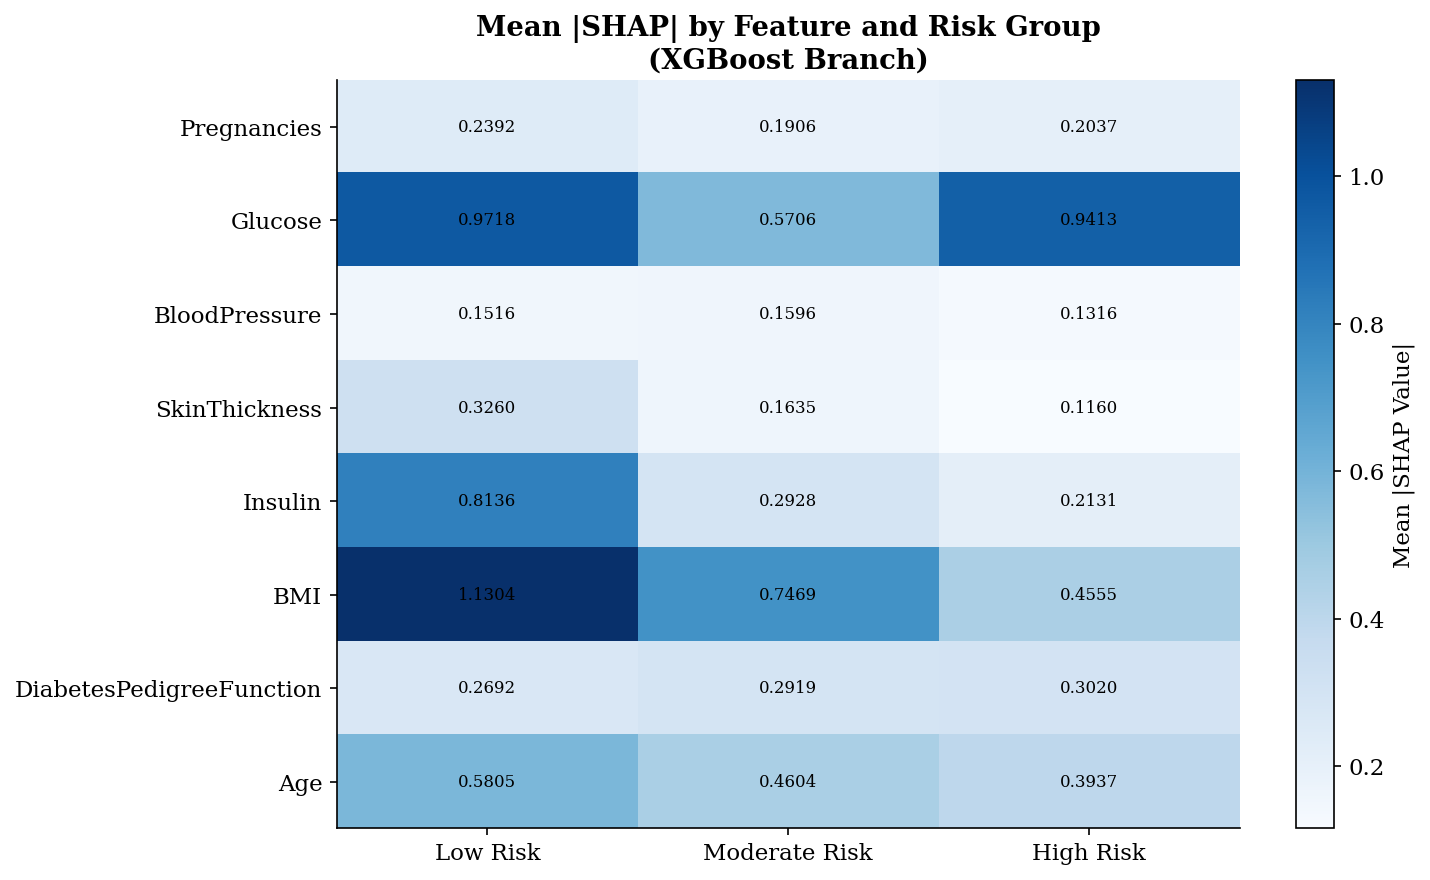

Saved: explainability_06_shap_by_risk_group.png


In [9]:
if SHAP_AVAILABLE:
    # Average SHAP values by risk group
    risk_shap = {}
    for grp in ['Low', 'Moderate', 'High']:
        mask = np.array([str(r) == grp for r in risk_group])
        risk_shap[grp] = np.abs(sv[mask]).mean(axis=0)

    shap_by_risk = pd.DataFrame(risk_shap, index=feature_names)
    print("Mean |SHAP| by Risk Group:")
    print(shap_by_risk.to_string())
    shap_by_risk.to_csv(TAB_DIR / 'shap_by_risk_group.csv')

    # Heatmap
    fig, ax = plt.subplots(figsize=(10, 6))
    import matplotlib.colors as mcolors
    im = ax.imshow(shap_by_risk.values, cmap='Blues', aspect='auto')
    ax.set_xticks(range(3))
    ax.set_xticklabels(['Low Risk', 'Moderate Risk', 'High Risk'])
    ax.set_yticks(range(len(feature_names)))
    ax.set_yticklabels(feature_names)
    plt.colorbar(im, ax=ax, label='Mean |SHAP Value|')
    ax.set_title('Mean |SHAP| by Feature and Risk Group\n(XGBoost Branch)', fontweight='bold')

    for i in range(len(feature_names)):
        for j, grp in enumerate(['Low', 'Moderate', 'High']):
            ax.text(j, i, f'{shap_by_risk.iloc[i, j]:.4f}', ha='center', va='center', fontsize=8)

    plt.tight_layout()
    plt.savefig(FIG_DIR / 'explainability_06_shap_by_risk_group.png', bbox_inches='tight')
    plt.show()
    print("Saved: explainability_06_shap_by_risk_group.png")